In [1]:
import uproot

import os
import sys
import glob

sys.path.append("..")
from globalsC2 import *

from v2Helpers import *

import matplotlib.pyplot as plt
import numpy as np

import CompHelpers.MCdataSet as MCH

CF4HOME: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4
COMP2PATH: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2
Welcome to JupyROOT 6.27/01


In [2]:
## Style setup — PDEStyle colors + larger fonts
import PDEStyle as PS
ms = PS.MyStyleSet()
ms.SetMPLcolors()   # sets matplotlib prop_cycle to PDEStyle colors

plt.rcParams.update({
    'font.size': 14,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 11,
})


In [5]:
class QuickClass(object):
  
  def __init__(self, fpath, height, rootFile, tt):
    
    self.fpath = fpath
    self.h = height
    self.rootFile = rootFile
    
    self.tt = tt
    
    self.histReturn = None
    self.binEdges = None
    self.binCounts = None
    self.binCenters = None
    
    return

# pBatch = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/ref_photonBombs/"
pBatch = "/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4cf4_newOptics/2batchOutput/ref_photonBomb_MS/"

folders = ["ref0", "ref05p", "ref10p"]

nbinScale = 100
fmap = {
  folders[0]:{"range":(0, 150), "ref":0, "fwide": 50},
  folders[1]: {"range":(0, 200), "ref":5, "fwide":50},
  folders[2]: {"range":(0, 400), "ref":10, "fwide":50}
  }

hmap = { 
  5:{"range":(5, 600), "nbins": 595/10},
  3: {"range":(5, 600), "nbins": 595/10},
  1.5: {"range":(5, 600), "nbins": 595/20}
}

fmap["ref0"]["range"]

(0, 150)

ref0
height =  5
False
height =  3


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_49034/1072022575.py:118: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax.plot(x_smooth, y_fit, 'r-', linewidth=2,


ValueError: zero-size array to reduction operation maximum which has no identity

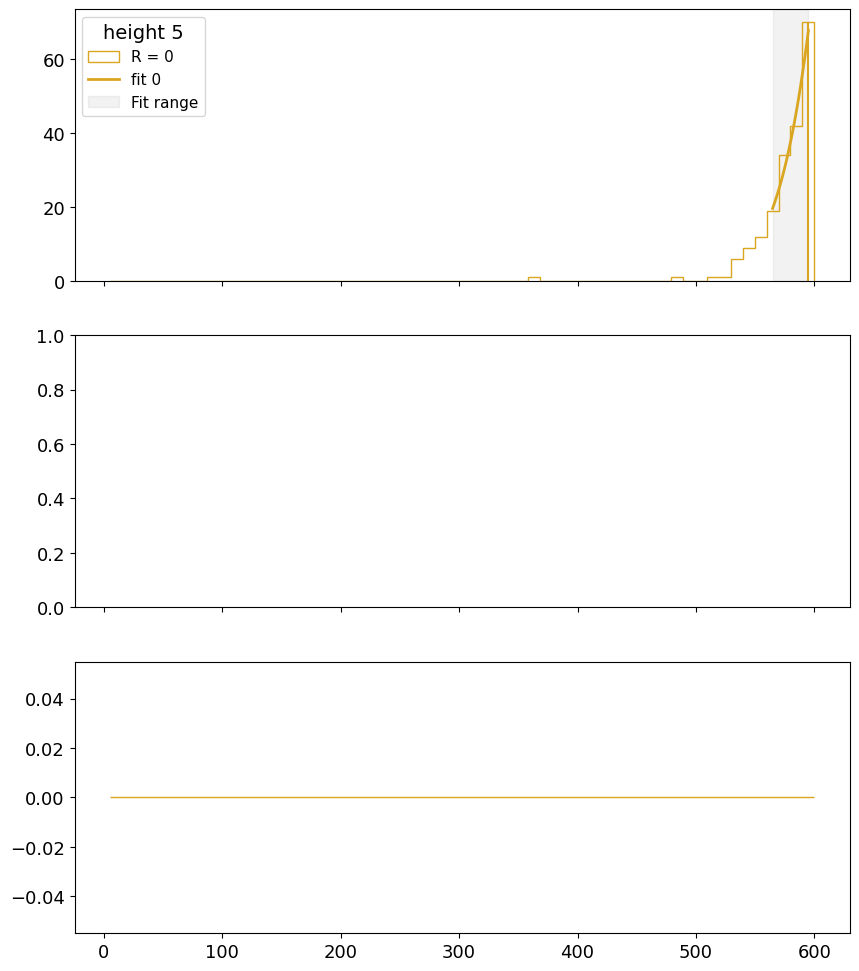

In [6]:


simGroups = [] # groups of quickClass

for folder in folders:
  path = os.path.join(pBatch, folder)
  # print(path)
  if not os.path.exists(path):
    print("path \n", path, "\n doesnt exist!")
  # print(os.path.exists(path))
  
  allFiles = os.listdir(path)
  root_files = [file for file in allFiles if file.endswith('.root')]

  # flist = glob.glob(path)
  # print(root_files)
  # print(flist)
  
  sims = []
  for fname in root_files:
    # print(fname)
    f = uproot.open(os.path.join(path, fname))
    ftt = f["simOutput"]
    # print(f.keys())
    # print(ftt.keys())
    
    h = -1
    if "1d5cm" in fname:
      h = 1.5
    elif "3cm" in fname:
      h = 3
    elif "5cm" in fname:
      h = 5
    
    shortPath = os.path.join(folder, fname)
    qc = QuickClass(fpath = shortPath, height = h, rootFile = f, tt = ftt)
    sims.append(qc)
    
  simGroups.append(sims)


fig, (ax1, ax3, ax2) = plt.subplots(3, 1, figsize = (10, 12), sharex = True)

# print(len(simGroups))
# print(len(simGroups[0]))

ms.ResetColorCycle()
for folder, sg in zip(folders, simGroups): # reflectivity/folder loop
  
  # print(type(sg[0]))
  print(folder)
  Ref = fmap[folder]["ref"]
  
  fitOpt = "bins"
  fitwide = fmap[folder]["fwide"]
  fwideFrac = 0.2
  fUpper = 3
  fLower = 3
  ms.GetNextColor()
  for sgh, ax in zip(sg, [ax1, ax2, ax3]): # loop on heights within each sim (ref)
    sim = sgh
    # simTT = sim.tt
    print("height = ", sim.h)
    # print("folder = ", sim.fpath)
    
    npeTouch = sim.tt["fTouchPE"].array()
    # print(len(npeTouch))
    
    counts, edges, _ = ax.hist(npeTouch, bins = int(hmap[sim.h]["nbins"]), histtype= "step", range = hmap[sim.h]["range"], label = f"R = {Ref}", color = ms.GetNextColor(1))
    
    # print(sim.histReturn)
    sim.binCounts = counts
    sim.binEdges = edges
    sim.binCenters = 0.5 * (edges[1:] + edges[:-1])
    
    # print(sim.binEdges)
    # print(sim.binCenters)
    
    # ax.vlines(sim.binCenters, ymin = min(counts), ymax = max(counts))
    
    ## doing fitting etc
    imaxPE = np.argmax(counts)
    maxPE = sim.binCenters[np.argmax(counts)]
    
    if fitOpt == "bins":
      maskedBins = sim.binCenters[imaxPE - fLower : imaxPE+fUpper]
      maskedCounts = counts[imaxPE - fLower : imaxPE+fUpper]
      maskedEdges = sim.binEdges[imaxPE - fLower:imaxPE+fUpper-1]
    elif fitOpt == "range":
      fMask = (sim.binCenters <= maxPE + fitwide) & (sim.binCenters >= maxPE - fitwide)
      maskedBins = sim.binCenters[fMask]
      maskedCount = count[fMask]
      maskedEdges = sim.binEdges[:-1][fMask]
    elif fitOpt == "fraction":
      fMask = (sim.binCenters < maxPE*(1+fwideFrac)) & (sim.binCenters > maxPE*(1-fwideFrac))
      maskedBins = sim.binCenters[fMask]
      maskedCount = count[fMask]
      maskedEdges = sim.binEdges[:-1][fMask]
    
    ax.vlines([maxPE], ymin = min(counts), ymax = max(counts), color = ms.GetNextColor(1))
    
    ## check mask
    # print(len(fMask), len(sim.binCenters), len(sim.binEdges))
    # ax.hist(x = maskedBins, bins = sim.binEdges[:-1][fMask], weights = sim.binCounts[fMask])
    
    ## check range
    # ax.hist(x = maskedBins, bins = maskedEdges, weights = maskedCounts)
    
    m = fit_histogram_gaussian(bin_centers = maskedBins, counts = maskedCounts)
    sim.fitRes = m
    
    # Generate smooth curve for the fit
    x_smooth = np.linspace(min(maskedBins), max(maskedBins), 100)
    y_fit = gaussian(x_smooth, 
                m.values['amplitude'], 
                m.values['mean'], 
                m.values['sigma'])

    # Plot the fit
    ax.plot(x_smooth, y_fit, 'r-', linewidth=2, 
            # label=f'Gaussian fit\nμ={m.values["mean"]:.1f}±{m.errors["mean"]:.1f}\nσ={m.values["sigma"]:.1f}±{m.errors["sigma"]:.1f}')
            label = f"fit {Ref}", color = ms.GetNextColor(1))

    # Plot just the fitted region for clarity
    ax.axvspan(min(maskedBins), max(maskedBins), alpha=0.1, color='gray', label='Fit range')

    print(m.valid)
    
    
    ax.legend(title = f"height {sim.h}")
    
ax3.set_xlim(0, 450)

    # break
  # # for rc in rcList:
  # #   
  # #   tt = f["tt"]
  # #   rc.mTimes = tt

  # path1 = os.path.join(pBatch, folders[0])
  # print(os.path.exists(path1))
  # print(path1)



In [7]:
hFits_1 = []
hFits_3 = []
hFits_5 = []
for sim in simGroups:
  
  for hsim in sim:
    hFits_1.append(m) if hsim.h == 1.5 else None
    hFits_3.append(m) if hsim.h == 3 else None
    hFits_5.append(m) if hsim.h == 5 else None
    
  
len(hFits_1)
len(hFits_3)
len(hFits_5)

means1 = [np.mean(sim.binCounts) for sim in simGroups[0]]
std1 = [np.std(sim.binCounts) for sim in simGroups[0]]

means3 = [np.mean(sim.binCounts) for sim in simGroups[1]]
std3 = [np.std(sim.binCounts) for sim in simGroups[1]]

means5 = [np.mean(sim.binCounts) for sim in simGroups[2]]
std5 = [np.std(sim.binCounts) for sim in simGroups[2]]

xH = [sim.h for sim in simGroups[0]]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize = (10, 8), sharex = True, height_ratios=[2,1])

ax1.errorbar(xH, [sim.fitRes.values["mean"] for sim in simGroups[0]], yerr = [sim.fitRes.values["sigma"] for sim in simGroups[0]],
             linestyle="None", marker = "d", markersize = 10, label = "R = 0")

ax1.errorbar(xH, means1, yerr = std1, linestyle = "None")

ax1.errorbar(xH, [sim.fitRes.values["mean"] for sim in simGroups[1]], yerr = [sim.fitRes.values["sigma"] for sim in simGroups[1]],
             linestyle="None", marker = "d", label = "R = 5")

ax1.errorbar(xH, means3, yerr = std3, linestyle = "None", label = "R5 mean")

ax1.errorbar(xH, [sim.fitRes.values["mean"] for sim in simGroups[2]], yerr = [sim.fitRes.values["sigma"] for sim in simGroups[2]],
             linestyle="None", marker = "d", label = "R = 20")

ax1.errorbar(xH, means3, yerr = std3, linestyle = "None", label = "R 20 mean")

ax1.legend()

TypeError: unsupported operand type(s) for /: 'NoneType' and 'int'